# Laboratorio 3 - Deep Learning
## Análisis Exploratorio del dataset ASL Alphabet

### Objetivo

El objetivo de este análisis exploratorio es comprender la estructura y las características del dataset ASL Alphabet antes del entrenamiento de modelos de aprendizaje profundo. Para ello se analiza la distribución de clases, el formato y resolución de las imágenes, así como ejemplos representativos y la variabilidad existente dentro de una misma clase.

### Importacion de librerias

In [1]:
import os
from collections import Counter

import numpy as np
import pandas as pd

import matplotlib.pyplot as plt
from PIL import Image

from pathlib import Path

### Carga de los datos

In [2]:
DATASET_PATH = Path("../data/asl_alphabet_train/asl_alphabet_train")

### Exploracion de estructura

In [3]:
classes = sorted([
    folder.name
    for folder in DATASET_PATH.iterdir()
    if folder.is_dir()
])

print(f"Número de clases: {len(classes)}")
print(classes)

Número de clases: 29
['A', 'B', 'C', 'D', 'E', 'F', 'G', 'H', 'I', 'J', 'K', 'L', 'M', 'N', 'O', 'P', 'Q', 'R', 'S', 'T', 'U', 'V', 'W', 'X', 'Y', 'Z', 'del', 'nothing', 'space']


### Conteo de imagenes por clase

In [4]:
image_counts = {}

for cls in classes:
    folder = DATASET_PATH / cls
    image_counts[cls] = len(list(folder.glob("*.jpg")))

counts_df = pd.DataFrame({
    "Clase": image_counts.keys(),
    "Cantidad": image_counts.values()
})

counts_df

,Clase,Cantidad
0,A,3000
1,B,2283
2,C,978
3,D,3000
4,E,3000
5,F,3000
6,G,3000
7,H,3000
8,I,3000
9,J,3000


### Grafica de distribucion

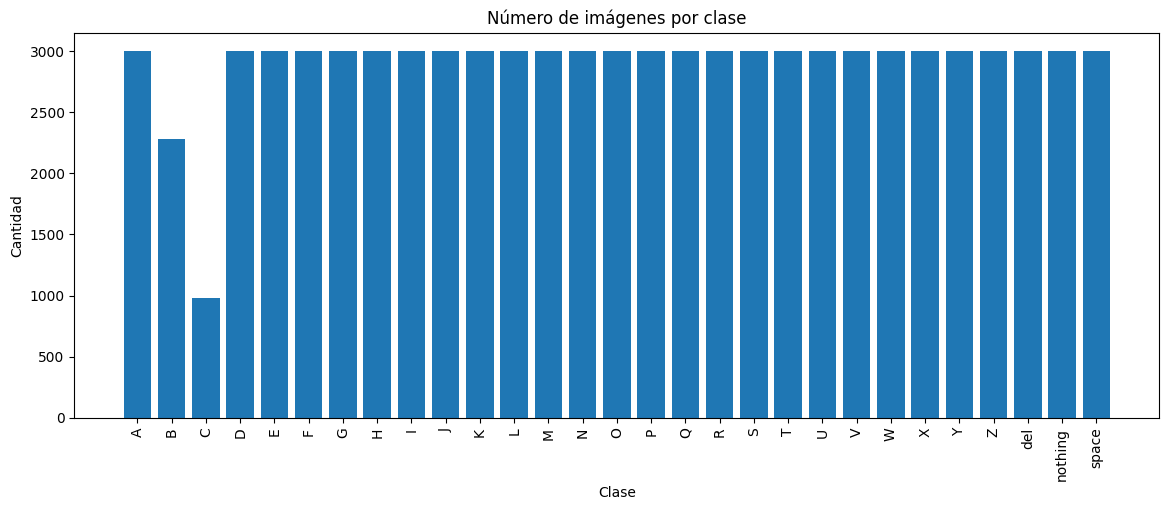

In [5]:
plt.figure(figsize=(14,5))

plt.bar(counts_df["Clase"], counts_df["Cantidad"])

plt.xticks(rotation=90)

plt.title("Número de imágenes por clase")

plt.xlabel("Clase")

plt.ylabel("Cantidad")

plt.show()

In [6]:
print("Resumen estadístico del número de imágenes por clase:")

counts_df.describe()

Resumen estadístico del número de imágenes por clase:


,Cantidad
count,29.000000
mean,2905.551724
std,393.876303
min,978.000000
25%,3000.000000
50%,3000.000000
75%,3000.000000
max,3000.000000


### Resolucion y formato de las imagenes

In [7]:
# Tomar una imagen de ejemplo de la primera clase
first_class = classes[0]
image_path = next((DATASET_PATH / first_class).glob("*.jpg"))

with Image.open(image_path) as img:
    print(f"Formato: {img.format}")
    print(f"Resolución: {img.size}")
    print(f"Modo de color: {img.mode}")

Formato: JPEG
Resolución: (200, 200)
Modo de color: RGB


### Ejemplos de imagenes del dataset

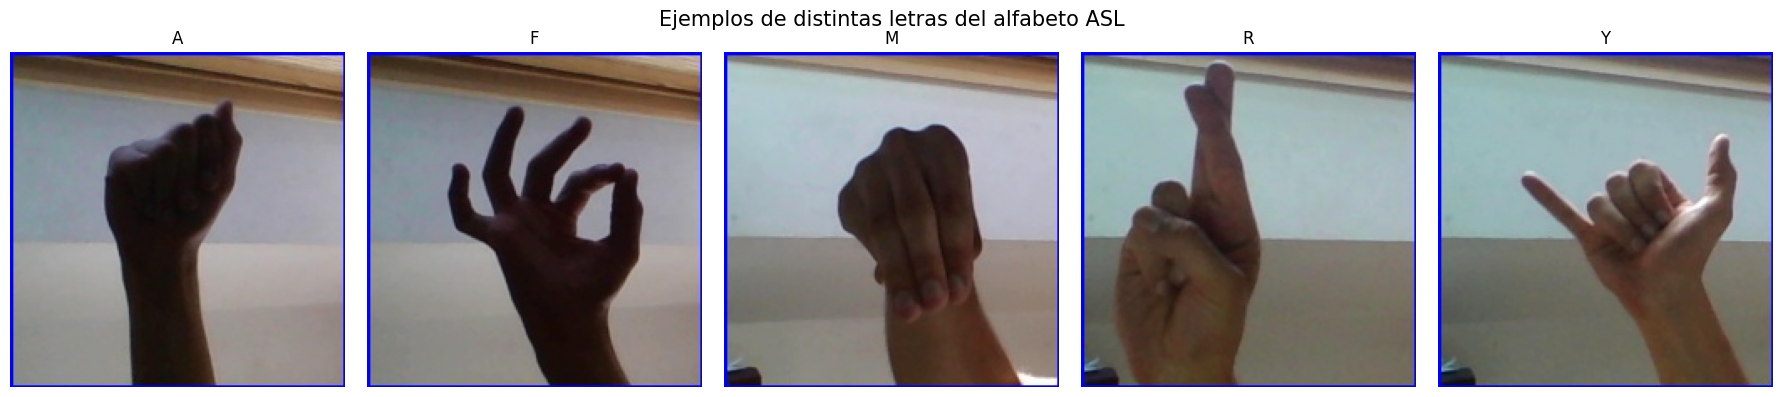

In [8]:
# Letras que mostraremos
sample_classes = ["A", "F", "M", "R", "Y"]

fig, axes = plt.subplots(1, len(sample_classes), figsize=(18,4))

for ax, letter in zip(axes, sample_classes):
    img_path = next((DATASET_PATH / letter).glob("*.jpg"))

    with Image.open(img_path) as img:
        ax.imshow(img)

    ax.set_title(letter)
    ax.axis("off")

plt.suptitle("Ejemplos de distintas letras del alfabeto ASL", fontsize=15)
plt.tight_layout()
plt.show()

Las imágenes muestran que cada clase corresponde a una configuración distinta de la mano. Aunque todas representan letras del alfabeto ASL, existen diferencias en la orientación, el ángulo y la posición de la mano respecto a la cámara.

### Variabilidad dentro de una misma clase

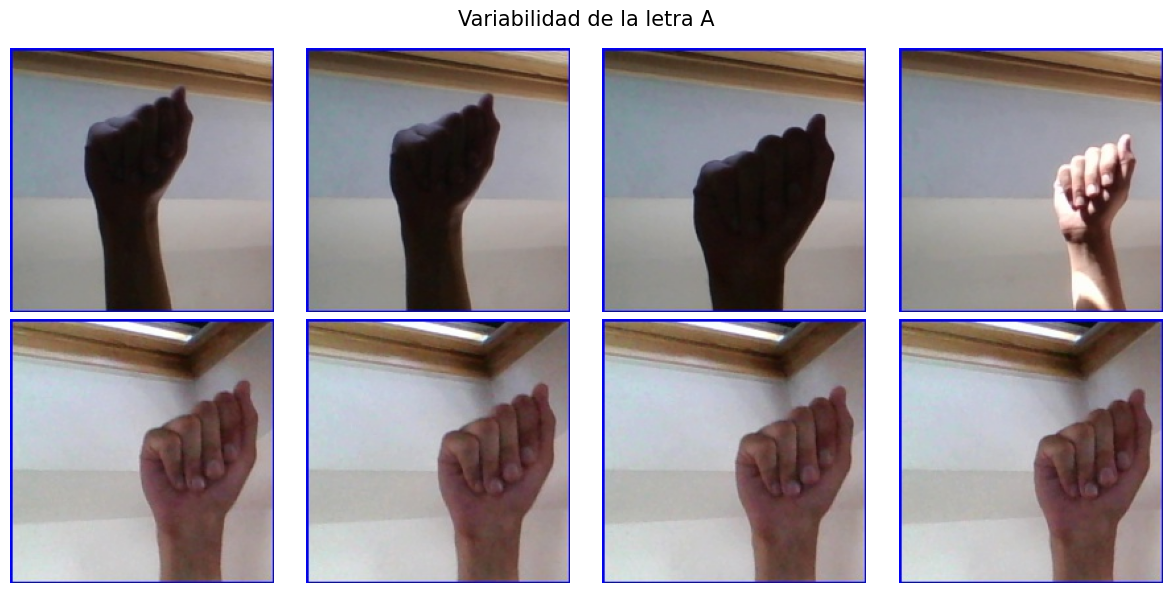

In [9]:
letter = "A"

image_paths = list((DATASET_PATH / letter).glob("*.jpg"))[:8]

fig, axes = plt.subplots(2,4, figsize=(12,6))

for ax, img_path in zip(axes.flatten(), image_paths):

    with Image.open(img_path) as img:
        ax.imshow(img)

    ax.axis("off")

plt.suptitle(f"Variabilidad de la letra {letter}", fontsize=15)
plt.tight_layout()
plt.show()

Al observar varias imágenes de la misma letra se aprecia que, aunque la seña es la misma, existen pequeñas variaciones entre muestras debido a cambios en la posición de la mano, iluminación y distancia respecto a la cámara. Esta variabilidad es importante porque permite entrenar modelos más robustos.

### Letras visualmente similares

Dataset completo en ..\data\asl_alphabet_train\asl_alphabet_train (29 clases), no se descarga nada.


Manifiesto: 20300 imágenes, 29 clases, ~700 img/clase


Pares de letras más parecidas visualmente (menor distancia = más parecidas):
  R - V: distancia=0.991
  V - W: distancia=1.102
  R - U: distancia=1.130
  U - V: distancia=1.134
  A - E: distancia=1.249
  V - Y: distancia=1.351
  W - Y: distancia=1.360
  S - Y: distancia=1.460


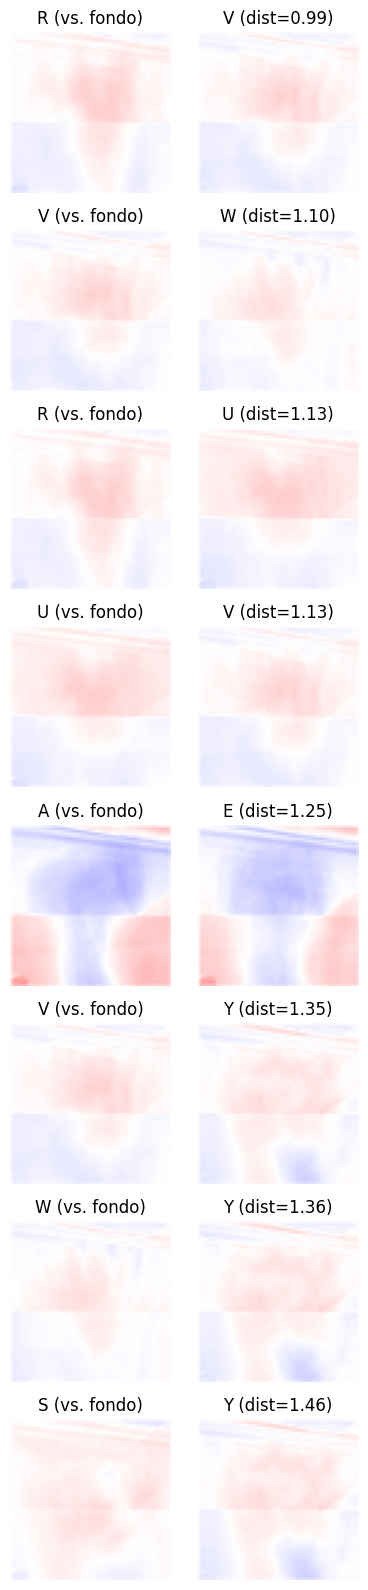

In [10]:
import sys
sys.path.append("../src")

from preprocessing import build_manifest, average_images_by_class, most_similar_pairs, plot_similar_pairs

# se usa la misma submuestra (700 img/clase) que consumirá el resto del equipo en data/processed/
manifest = build_manifest(raw_dir=DATASET_PATH)
averages = average_images_by_class(manifest)
top_pairs = most_similar_pairs(averages, top_n=8)

print("Pares de letras más parecidas visualmente (menor distancia = más parecidas):")
for a, b, d in top_pairs:
    print(f"  {a} - {b}: distancia={d:.3f}")

plot_similar_pairs(averages, top_pairs, out_path="../images/letras_similares.png")

Los pares de letras con menor distancia entre sus imágenes promedio (más parecidas visualmente)
son: R-V (0.991), V-W (1.102), R-U (1.130), U-V (1.134), A-E (1.249), V-Y (1.351), W-Y (1.360) y
S-Y (1.460).

En la figura cada clase se muestra restándole el promedio global de las 29 clases: como todas las
fotos se tomaron en el mismo escenario, el fondo es casi idéntico en todas y al quitarlo se nota
dónde está la mano. El rojo marca las zonas más oscuras que el fondo común y el azul las más
claras. Esta resta es solo para poder ver la figura, no afecta las distancias: restarle lo mismo a
dos imágenes no cambia la diferencia entre ellas.

El grupo R/U/V/W aparece repetido en casi todos los pares y en la figura se ve por qué: las cuatro
comparten la misma mancha vertical en el centro, que corresponde a los dedos extendidos hacia
arriba, y solo cambian en la separación o el cruce de los dedos. Y se separa un poco del grupo por
la zona inferior derecha, donde queda el pulgar extendido. El par A-E tiene una forma distinta al
resto, más ancha y compacta, consistente con que ambas se hacen con la mano cerrada en puño y solo
cambia la posición del pulgar.

Hay que tener en cuenta que promediar cientos de imágenes difumina las diferencias finas: este
análisis sirve para anticipar qué clases podrían confundirse, pero la confirmación real vendrá de
la matriz de confusión de los modelos entrenados.

### Construcción del split train/validación/prueba

El conjunto de datos se divide en 70% entrenamiento, 15% validación y 15% prueba, de forma
estratificada por clase (`stratify=label` en `stratified_split`, en `src/preprocessing.py`). Esto
mantiene la misma proporción de cada una de las 29 clases en los tres subconjuntos, en vez de un
split puramente aleatorio que podría dejar alguna clase subrepresentada en validación o prueba.

El set de prueba oficial de Kaggle no se usa para evaluar los modelos: el enunciado del laboratorio
indica que trae deliberadamente pocas imágenes por clase, precisamente para forzar a construir un
conjunto de prueba propio a partir de los datos de entrenamiento disponibles. Por eso el split se
genera aquí, sobre el mismo manifiesto de imágenes que se usa para el resto del análisis.

### Justificación de resolución y submuestra

Las imágenes se redimensionan de 200x200 a 64x64 píxeles (`IMG_SIZE` en `src/preprocessing.py`).
Esta reducción baja considerablemente el costo de cómputo de cargar y entrenar sobre el dataset,
manteniendo suficiente detalle para distinguir la forma de la mano en cada seña.

Del total de 3000 imágenes disponibles por clase, se toma una submuestra aleatoria de 700
(`N_PER_CLASS` en `src/preprocessing.py`), dentro del rango de 500 a 800 sugerido en el enunciado
del laboratorio. Esto reduce el tiempo de carga y entrenamiento sin perder la variabilidad ya
observada dentro de cada clase (distintas posiciones de mano, iluminación y distancia respecto a
la cámara).

### Conclusion

El análisis de la distribución de clases muestra que el dataset está casi balanceado: 27 de las 29
clases contienen exactamente 3000 imágenes, mientras que B tiene 2283 y C tiene 978. Esto se
refleja en la media de 2905.55 imágenes por clase y una desviación estándar de 393.88, distinta de
cero por las dos clases incompletas. Aun así, incluso la clase con menos imágenes (C, con 978)
tiene más del doble del tamaño de submuestra que se usa por clase (700, ver justificación de
submuestra más abajo), por lo que este desbalance no afecta el entrenamiento y no se requieren
técnicas de compensación como sobremuestreo, submuestreo o ponderación de clases.